<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


<h1>Extracting and Visualizing Stock Data</h1>
<h2>Description</h2>


Extracting essential data from a dataset and displaying it is a necessary part of data science; therefore individuals can make correct decisions based on the data. In this assignment, you will extract some stock data, you will then display this data in a graph.


<h2>Table of Contents</h2>
<div class="alert alert-block alert-info" style="margin-top: 20px">
    <ul>
        <li>Define a Function that Makes a Graph</li>
        <li>Question 1: Use yfinance to Extract Stock Data</li>
        <li>Question 2: Use Webscraping to Extract Tesla Revenue Data</li>
        <li>Question 3: Use yfinance to Extract Stock Data</li>
        <li>Question 4: Use Webscraping to Extract GME Revenue Data</li>
        <li>Question 5: Plot Tesla Stock Graph</li>
        <li>Question 6: Plot GameStop Stock Graph</li>
    </ul>
<p>
    Estimated Time Needed: <strong>30 min</strong></p>
</div>

<hr>


> **Required for peer grading:** Use **Kernel → Restart Kernel and Run All Cells**. Do not run single cells out of order. Wait until both graphs and all four 5-row tables display; then press **Ctrl+S**. Download the executed `.ipynb` and capture six screenshots from this running notebook. **Never submit an unexecuted notebook or screenshots of code without output.**

***Note***:- If you are working Locally using anaconda, please uncomment the following code and execute it.
Use the version as per your python version.


In [1]:
# Optional, only if a package is missing:
# %pip install yfinance beautifulsoup4 matplotlib pandas requests
print("Notebook setup: using the Python packages already installed in your JupyterLab environment.")

Notebook setup: using the Python packages already installed in your JupyterLab environment.

In [2]:
import yfinance as yf
import pandas as pd
import requests
from bs4 import BeautifulSoup

In Python, you can ignore warnings using the warnings module. You can use the filterwarnings function to filter or ignore specific warning messages or categories.


In [3]:
import warnings
# Ignore all warnings
warnings.filterwarnings("ignore", category=FutureWarning)

## Define Graphing Function


In this section, we define the function `make_graph`. **You don't have to know how the function works, you should only care about the inputs. It takes a dataframe with stock data (dataframe must contain Date and Close columns), a dataframe with revenue data (dataframe must contain Date and Revenue columns), and the name of the stock.**


In [4]:
import matplotlib.pyplot as plt

def make_graph(stock_data, revenue_data, stock):
    """Display the course's two historical charts from cleaned stock/revenue data."""
    required_stock = {"Date", "Close"}
    required_revenue = {"Date", "Revenue"}
    assert required_stock.issubset(stock_data.columns), f"{stock}: missing stock columns"
    assert required_revenue.issubset(revenue_data.columns), f"{stock}: missing revenue columns"

    stock_plot = stock_data[["Date", "Close"]].copy()
    revenue_plot = revenue_data[["Date", "Revenue"]].copy()
    stock_plot["Date"] = pd.to_datetime(stock_plot["Date"], utc=True, errors="coerce").dt.tz_localize(None)
    revenue_plot["Date"] = pd.to_datetime(revenue_plot["Date"], errors="coerce")
    stock_plot["Close"] = pd.to_numeric(stock_plot["Close"], errors="coerce")
    revenue_plot["Revenue"] = pd.to_numeric(
        revenue_plot["Revenue"].astype(str).str.replace(r"[$,]", "", regex=True),
        errors="coerce",
    )
    stock_plot = stock_plot.dropna().query("Date <= '2021-06-14'").sort_values("Date")
    revenue_plot = revenue_plot.dropna().query("Date <= '2021-04-30'").sort_values("Date")
    assert not stock_plot.empty, f"{stock}: no valid stock data in chart period"
    assert not revenue_plot.empty, f"{stock}: no valid revenue data in chart period"

    fig, axes = plt.subplots(2, 1, figsize=(12, 8))
    axes[0].plot(stock_plot["Date"], stock_plot["Close"], color="blue")
    axes[0].set_title(f"{stock} - Historical Share Price")
    axes[0].set_xlabel("Date")
    axes[0].set_ylabel("Price ($US)")
    axes[0].grid(alpha=0.2)
    axes[1].plot(revenue_plot["Date"], revenue_plot["Revenue"], color="green")
    axes[1].set_title(f"{stock} - Historical Revenue")
    axes[1].set_xlabel("Date")
    axes[1].set_ylabel("Revenue ($US Millions)")
    axes[1].grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

Use the make_graph function that we’ve already defined. You’ll need to invoke it in questions 5 and 6 to display the graphs and create the dashboard. 
> **Note: You don’t need to redefine the function for plotting graphs anywhere else in this notebook; just use the existing function.**


## Question 1: Use yfinance to Extract Stock Data


Using the `Ticker` function enter the ticker symbol of the stock we want to extract data on to create a ticker object. The stock is Tesla and its ticker symbol is `TSLA`.


Using the ticker object and the function `history` extract stock information and save it in a dataframe named `tesla_data`. Set the `period` parameter to ` "max" ` so we get information for the maximum amount of time.


**Reset the index** using the `reset_index(inplace=True)` function on the tesla_data DataFrame and display the first five rows of the `tesla_data` dataframe using the `head` function. Take a screenshot of the results and code from the beginning of Question 1 to the results below.


In [5]:
tesla = yf.Ticker("TSLA")

tesla_data = tesla.history(period="max")
assert not tesla_data.empty, "Tesla stock history is empty; check the Yahoo Finance connection."

tesla_data.reset_index(inplace=True)
assert {"Date", "Open", "High", "Low", "Close"}.issubset(tesla_data.columns)
tesla_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


## Question 2: Use Webscraping to Extract Tesla Revenue Data


Use the `requests` library to download the webpage https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm Save the text of the response as a variable named `html_data`.


Parse the html data using `beautiful_soup` using parser i.e `html5lib` or `html.parser`.


Using `BeautifulSoup` or the `read_html` function extract the table with `Tesla Revenue` and store it into a dataframe named `tesla_revenue`. The dataframe should have columns `Date` and `Revenue`.


<details><summary>Step-by-step instructions</summary>

```

Here are the step-by-step instructions:

1. Create an Empty DataFrame
2. Find the Relevant Table
3. Check for the Tesla Quarterly Revenue Table
4. Iterate Through Rows in the Table Body
5. Extract Data from Columns
6. Append Data to the DataFrame

```
</details>


<details><summary>Click here if you need help locating the table</summary>

```
    
Below is the code to isolate the table, you will now need to loop through the rows and columns like in the previous lab
    
soup.find_all("tbody")[1]
    
If you want to use the read_html function the table is located at index 1

We are focusing on quarterly revenue in the lab.
```

</details>


Execute the following line to remove the comma and dollar sign from the `Revenue` column. 


Execute the following lines to remove an null or empty strings in the Revenue column.


Display the last 5 row of the `tesla_revenue` dataframe using the `tail` function. Take a screenshot of the results.


In [6]:
"""Download the IBM course snapshot of Tesla revenue."""
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"
response = requests.get(url, timeout=30)
response.raise_for_status()
html_data = response.text

soup_tesla = BeautifulSoup(html_data, "html.parser")

# Parse the quarterly Tesla revenue table (second table in the IBM HTML snapshot).
tables_tesla = soup_tesla.find_all("table")
assert len(tables_tesla) >= 2, "Tesla revenue page did not return the expected two tables"
quarterly_table = tables_tesla[1]
rows = []
for tr in quarterly_table.find_all("tr"):
    td = tr.find_all("td")
    if len(td) >= 2:
        rows.append({"Date": td[0].get_text(strip=True),
                     "Revenue": td[1].get_text(strip=True)})
tesla_revenue = pd.DataFrame(rows, columns=["Date", "Revenue"])
assert not tesla_revenue.empty, "Tesla quarterly revenue table was empty."

# Strip formatting before converting the quarterly USD-million values to numbers.
tesla_revenue["Revenue"] = (
    tesla_revenue["Revenue"].astype(str).str.replace(r"[$,]", "", regex=True).str.strip()
)

tesla_revenue["Revenue"] = pd.to_numeric(tesla_revenue["Revenue"], errors="coerce")
tesla_revenue = tesla_revenue.dropna(subset=["Date", "Revenue"]).copy()
tesla_revenue["Revenue"] = tesla_revenue["Revenue"].astype(int)
assert not tesla_revenue.empty

tesla_revenue.tail()

,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
52,2009-09-30,46
53,2009-06-30,27


## Question 3: Use yfinance to Extract Stock Data


Using the `Ticker` function enter the ticker symbol of the stock we want to extract data on to create a ticker object. The stock is GameStop and its ticker symbol is `GME`.


Using the ticker object and the function `history` extract stock information and save it in a dataframe named `gme_data`. Set the `period` parameter to ` "max" ` so we get information for the maximum amount of time.


**Reset the index** using the `reset_index(inplace=True)` function on the gme_data DataFrame and display the first five rows of the `gme_data` dataframe using the `head` function. Take a screenshot of the results and code from the beginning of Question 3 to the results below.


In [8]:
gme = yf.Ticker("GME")

gme_data = gme.history(period="max")
assert not gme_data.empty, "GameStop stock history is empty; check the Yahoo Finance connection."

gme_data.reset_index(inplace=True)
assert {"Date", "Open", "High", "Low", "Close"}.issubset(gme_data.columns)
gme_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620128,1.693350,1.603296,1.691666,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716074,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658002,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666417,1.666417,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0


## Question 4: Use Webscraping to Extract GME Revenue Data


Use the `requests` library to download the webpage https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html. Save the text of the response as a variable named `html_data_2`


Parse the html data using `beautiful_soup` using parser i.e `html5lib` or `html.parser`.


Using `BeautifulSoup` or the `read_html` function extract the table with `GameStop Revenue` and store it into a dataframe named `gme_revenue`. The dataframe should have columns `Date` and `Revenue`. Make sure the comma and dollar sign is removed from the `Revenue` column.


> **Note: Use the method similar to what you did in question 2.**  


<details><summary>Click here if you need help locating the table</summary>

```
    
Below is the code to isolate the table, you will now need to loop through the rows and columns like in the previous lab
    
soup.find_all("tbody")[1]
    
If you want to use the read_html function the table is located at index 1


```

</details>


Remove the comma and dollar sign, an null or empty strings from the Revenue column.


Display the last five rows of the `gme_revenue` dataframe using the `tail` function. Take a screenshot of the results.


In [9]:
"""Download the IBM course snapshot of GameStop revenue."""
url_gme = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html"
response_gme = requests.get(url_gme, timeout=30)
response_gme.raise_for_status()
html_data_2 = response_gme.text

soup_gme = BeautifulSoup(html_data_2, "html.parser")

# Parse the quarterly GameStop revenue table (second table in the IBM HTML snapshot).
tables_gme = soup_gme.find_all("table")
assert len(tables_gme) >= 2, "GameStop revenue page did not return the expected two tables"
quarterly_table_gme = tables_gme[1]
rows_gme = []
for tr in quarterly_table_gme.find_all("tr"):
    td = tr.find_all("td")
    if len(td) >= 2:
        rows_gme.append({"Date": td[0].get_text(strip=True),
                         "Revenue": td[1].get_text(strip=True)})
gme_revenue = pd.DataFrame(rows_gme, columns=["Date", "Revenue"])
assert not gme_revenue.empty, "GameStop quarterly revenue table was empty."

gme_revenue["Revenue"] = (
    gme_revenue["Revenue"].astype(str).str.replace(r"[$,]", "", regex=True).str.strip()
)
gme_revenue["Revenue"] = pd.to_numeric(gme_revenue["Revenue"], errors="coerce")
gme_revenue = gme_revenue.dropna(subset=["Date", "Revenue"]).copy()
gme_revenue["Revenue"] = gme_revenue["Revenue"].astype(int)
assert not gme_revenue.empty

gme_revenue.tail()

,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


## Question 5: Plot Tesla Stock Graph


Use the `make_graph` function to graph the Tesla Stock Data, also provide a title for the graph. Note the graph will only show data upto June 2021.


<details><summary>Hint</summary>

```

You just need to invoke the make_graph function with the required parameter to print the graphs.The structure to call the `make_graph` function is `make_graph(tesla_data, tesla_revenue, 'Tesla')`.

```
    
</details>


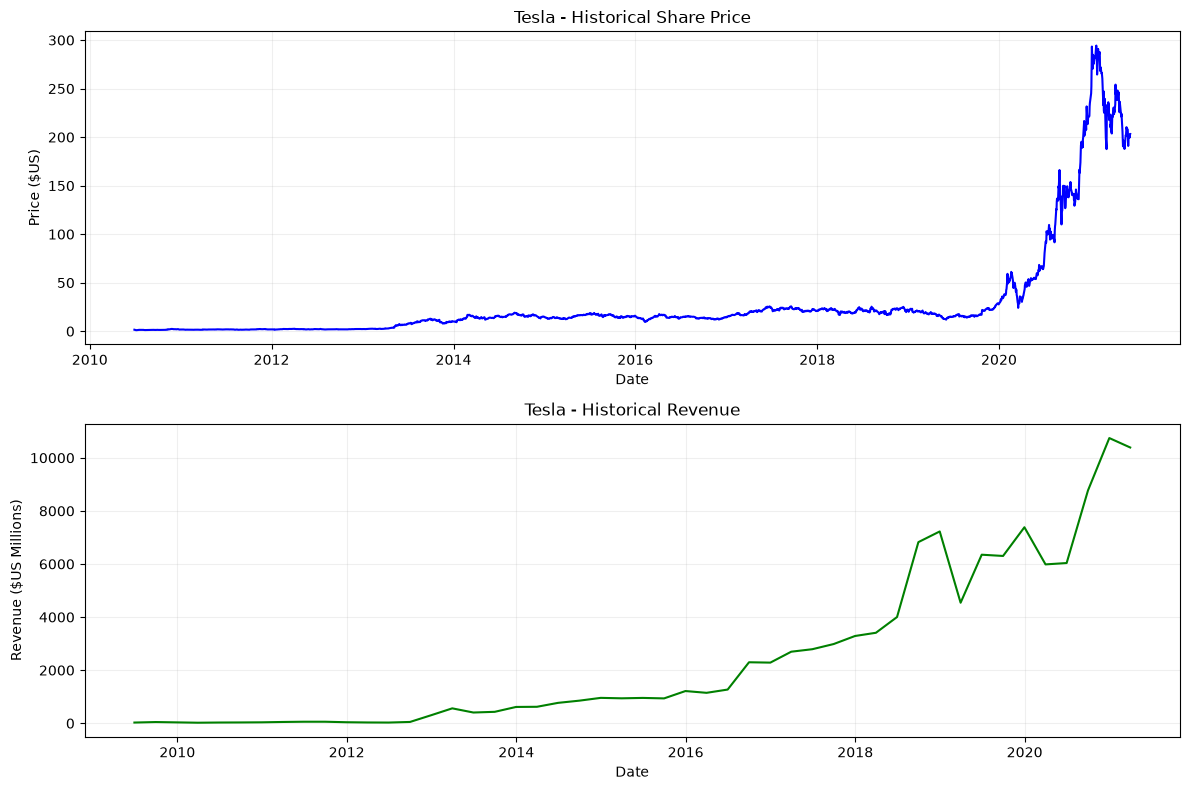

In [7]:
make_graph(tesla_data, tesla_revenue, "Tesla")

## Question 6: Plot GameStop Stock Graph


Use the `make_graph` function to graph the GameStop Stock Data, also provide a title for the graph. The structure to call the `make_graph` function is `make_graph(gme_data, gme_revenue, 'GameStop')`. Note the graph will only show data upto June 2021.


<details><summary>Hint</summary>

```

You just need to invoke the make_graph function with the required parameter to print the graphs.The structure to call the `make_graph` function is `make_graph(gme_data, gme_revenue, 'GameStop')`

```
    
</details>


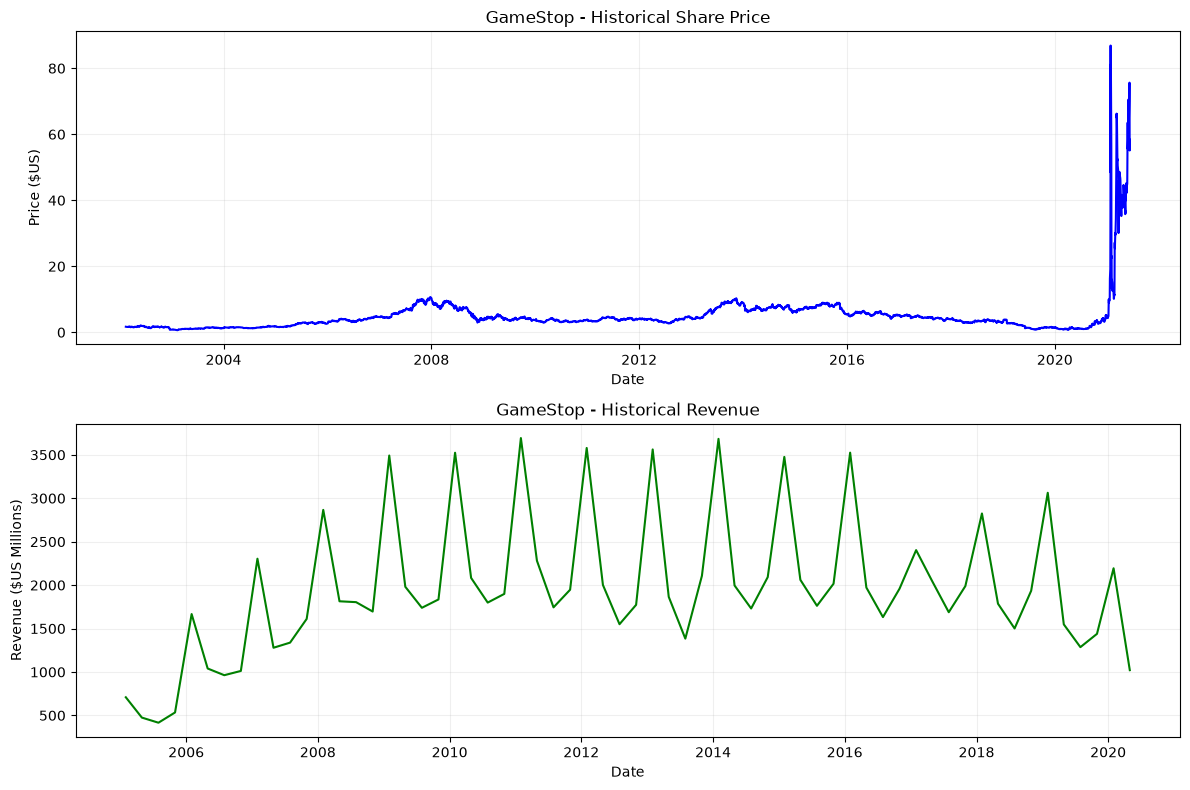

In [11]:
make_graph(gme_data, gme_revenue, "GameStop")

### Final validation (run after the six exercises)
These checks verify that the downloaded stock and quarterly revenue datasets are non-empty. Confirm the two graphs appear immediately above before saving and uploading the notebook.

In [10]:
# Final audit: run all cells top-to-bottom; do not run exercise cells out of order.
for label, frame, columns in [
    ("Tesla stock", tesla_data, {"Date", "Open", "High", "Low", "Close"}),
    ("Tesla quarterly revenue", tesla_revenue, {"Date", "Revenue"}),
    ("GameStop stock", gme_data, {"Date", "Open", "High", "Low", "Close"}),
    ("GameStop quarterly revenue", gme_revenue, {"Date", "Revenue"}),
]:
    assert not frame.empty, f"{label}: empty table"
    assert columns.issubset(frame.columns), f"{label}: missing {columns - set(frame.columns)}"
    if "Revenue" in frame.columns:
        assert pd.api.types.is_numeric_dtype(frame["Revenue"]), f"{label}: revenue is not numeric"
    print(f"PASS: {label} — {len(frame):,} rows")
print("PASS: Both stock histories and both revenue tables are valid. Check that Q5/Q6 charts are visible.")

assert float(tesla_revenue.iloc[-1]["Revenue"]) == 27, "Tesla quarter-end history is not the intended course snapshot (last value should be 27)"
assert pd.to_datetime(gme_data.iloc[0]["Date"]).year == 2002, "GME history did not start in 2002"
print("PASS: Tesla earliest quarterly revenue is 27 million USD")
print("PASS: Stock tables and revenue charts ready for screenshots")


PASS: Tesla stock — 4,097 rows
PASS: Tesla quarterly revenue — 53 rows
PASS: GameStop stock — 6,205 rows
PASS: GameStop quarterly revenue — 62 rows
PASS: Both stock histories and both revenue tables are valid. Check that Q5/Q6 charts are visible.
PASS: Tesla earliest quarterly revenue is 27 million USD
PASS: Stock tables and revenue charts ready for screenshots

<h2>About the Authors:</h2> 

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.

Azim Hirjani


## Change Log

| Date (YYYY-MM-DD) | Version | Changed By    | Change Description        |
| ----------------- | ------- | ------------- | ------------------------- |
| 2022-02-28        | 1.2     | Lakshmi Holla | Changed the URL of GameStop |
| 2020-11-10        | 1.1     | Malika Singla | Deleted the Optional part |
| 2020-08-27        | 1.0     | Malika Singla | Added lab to GitLab       |

<hr>


Copyright © 2020 IBM Corporation. All rights reserved.
